Question 4.1 Random protocol: a stratified random split with 70 % of the videos for training and 30 % for testing, 
repeated 30 times with a fixed seed (StratifiedShuffleSplit). Report the mean and standard 
deviation of accuracy and macro F1, and the confusion matrix summed over the repetitions.

In [2]:

from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

import pandas as pd
import numpy as np

# Load video-level features and held-out test-video IDs
video_data = pd.read_parquet("new_3.2_video_measurements.gzip")
testIndex = pd.read_parquet("testIndex.gzip")

# Exclude held-out test actors
dev_data = video_data[
    ~video_data["video"].isin(testIndex["video"])
].copy()

# Separate feature matrix X and target labels y
feature_cols = [
    c for c in dev_data.select_dtypes(include="number").columns
    if c != "frame"
]

X = dev_data[feature_cols]
y = dev_data["emotion"]

classes = sorted(y.unique())

# Sanity checks
print("Development videos:", len(dev_data))
print("Number of features:", len(feature_cols))
print("Emotion counts:\n", y.value_counts())

# Required pipeline: scale features, then train an RBF SVM
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(kernel="rbf"))
])

splitter = StratifiedShuffleSplit(
    n_splits=30,
    test_size=0.30,
    random_state=42
)

accuracies = []
macro_f1_scores = []
summed_cm = np.zeros((len(classes), len(classes)), dtype=int)

for train_idx, test_idx in splitter.split(X, y):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)

    accuracies.append(accuracy_score(y_test, y_pred))
    macro_f1_scores.append(
        f1_score(y_test, y_pred, average="macro")
    )

    summed_cm += confusion_matrix(
        y_test, y_pred, labels=classes
    )

print(f"Accuracy: {np.mean(accuracies):.3f} ± {np.std(accuracies):.3f}")
print(f"Macro F1: {np.mean(macro_f1_scores):.3f} ± {np.std(macro_f1_scores):.3f}")
print("Class order:", classes)
print("Summed confusion matrix:\n", summed_cm)


Development videos: 1200
Number of features: 55
Emotion counts:
 emotion
Calm         160
Happy        160
Sad          160
Angry        160
Fearful      160
Disgust      160
Surprised    160
Neutral       80
Name: count, dtype: int64
Accuracy: 0.763 ± 0.024
Macro F1: 0.761 ± 0.023
Class order: ['Angry', 'Calm', 'Disgust', 'Fearful', 'Happy', 'Neutral', 'Sad', 'Surprised']
Summed confusion matrix:
 [[1136    5   61   44    0   13   51  130]
 [  22 1266    4    8   18   69   48    5]
 [  77   26 1198   16   10    8   67   38]
 [  82    8   26 1017   21    6  155  125]
 [  36  145    1    0 1241    0    1   16]
 [   3   33    0   27    0  592   57    8]
 [   8   70  117   67   38  115  941   84]
 [  73   40   60  234   23   62  100  848]]


The mean accuracy was 0.763 ± 0.024, while the mean macro F1-score was 0.761 ± 0.023. The relatively small standard deviations indicate that the results were reasonably consistent across the random splits.

As for the confusion matrix, "Calm", "Disgust" and "Happy" were classified relatively well. "Surprised" was often mistaken for "Fearful" and less often as "Sad". "Sad" was often mistaken for "Neutral" or "Disgust". "Fearful" was often mistaken for "Sad" or "Surprised". "Angry" got often mistaken for "Surprised". And finally, even though it was relatively well classified, "Happy" was also often mistaken for "Calm".

Question 4.2 Leave-one-subject-out (LOSO) protocol: LeaveOneGroupOut with the actor as the group, 20 folds, 
one per development actor. Report the same metrics, and the distribution of the macro F1 over the 
20 actors.

Development videos: 1200
Number of features: 55
Emotion counts:
 emotion
Calm         160
Happy        160
Sad          160
Angry        160
Fearful      160
Disgust      160
Surprised    160
Neutral       80
Name: count, dtype: int64
Mean accuracy: 0.592 ± 0.113
Mean macro F1: 0.568 ± 0.122

Class order: ['Angry', 'Calm', 'Disgust', 'Fearful', 'Happy', 'Neutral', 'Sad', 'Surprised']
Summed confusion matrix:
 [[117   0  11   8   0   2   5  17]
 [  6 103   1   3  14  13  18   2]
 [ 13   8  98   6   8   2  13  12]
 [ 18   4   8  90   3   5  20  12]
 [  7  27   3   0 113   1   1   8]
 [  0   5   1   4   1  57  10   2]
 [  3  13  17  18  10  17  68  14]
 [ 12   6  16  29   4  13  16  64]]

Results for each held-out actor:
actor  accuracy  macro_f1
   02  0.583333  0.537703
   03  0.616667  0.526129
   04  0.533333  0.512707
   05  0.600000  0.540506
   06  0.450000  0.351247
   07  0.633333  0.574444
   08  0.616667  0.543560
   09  0.666667  0.674200
   10  0.883333  0.881387
   11  0.400

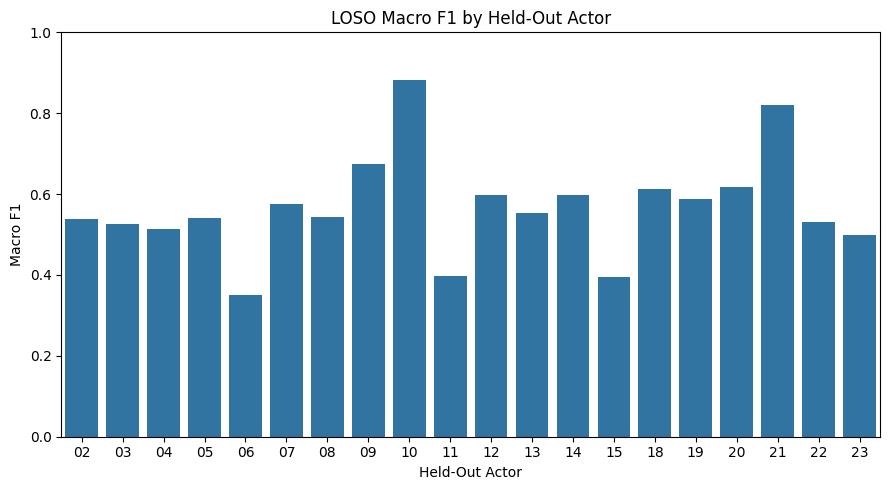

In [2]:
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

# Load video-level features and held-out test-video IDs
video_data = pd.read_parquet("new_3.2_video_measurements.gzip")
testIndex = pd.read_parquet("testIndex.gzip")

# Exclude held-out test actors
dev_data = video_data[
    ~video_data["video"].isin(testIndex["video"])
].copy()

# Extract actor ID from the video filename
dev_data["actor"] = (
    dev_data["video"]
    .str.replace(".csv", "", regex=False)
    .str.split("-")
    .str[-1]
)

# Separate feature matrix X and target labels y
feature_cols = [
    c for c in dev_data.select_dtypes(include="number").columns
    if c != "frame"
]

X = dev_data[feature_cols]
y = dev_data["emotion"]
groups = dev_data["actor"]

# Sanity checks
print("Development videos:", len(dev_data))
print("Number of features:", len(feature_cols))
print("Emotion counts:\n", y.value_counts())

# Required pipeline: scale features, then train an RBF SVM
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(kernel="rbf"))
])

logo = LeaveOneGroupOut()
classes = sorted(y.unique())

accuracies = []
macro_f1_scores = []
summed_cm = np.zeros((len(classes), len(classes)), dtype=int)
actor_results = []

for train_idx, test_idx in logo.split(X, y, groups=groups):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    # Identify the actor held out in this fold
    held_out_actor = groups.iloc[test_idx].iloc[0]

    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    macro_f1 = f1_score(
        y_test, y_pred,
        average="macro",
        labels=classes,
        zero_division=0
    )

    accuracies.append(accuracy)
    macro_f1_scores.append(macro_f1)

    actor_results.append({
        "actor": held_out_actor,
        "accuracy": accuracy,
        "macro_f1": macro_f1
    })

    summed_cm += confusion_matrix(
        y_test, y_pred, labels=classes
    )

# Overall results across the 20 held-out actors
print(f"Mean accuracy: {np.mean(accuracies):.3f} ± {np.std(accuracies):.3f}")
print(f"Mean macro F1: {np.mean(macro_f1_scores):.3f} ± {np.std(macro_f1_scores):.3f}")

print("\nClass order:", classes)
print("Summed confusion matrix:\n", summed_cm)

# Distribution of results across actors
actor_results_df = pd.DataFrame(actor_results).sort_values("actor")
print("\nResults for each held-out actor:")
print(actor_results_df.to_string(index=False))

# Visualise macro F1 distribution across actors
plt.figure(figsize=(9, 5))
sns.barplot(
    data=actor_results_df,
    x="actor",
    y="macro_f1"
)
plt.title("LOSO Macro F1 by Held-Out Actor")
plt.xlabel("Held-Out Actor")
plt.ylabel("Macro F1")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

Question 4.3 Compare 4.1 and 4.2. Which question does each protocol answer? Which of them estimates the performance on a person whose face the model has never seen? Explain the difference in terms of 1.3. Which protocol must be used in the rest of the project?

The random split protocol (4.1) estimates how well the model classifies videos randomly sampled from the same population of actors represented in the training data. Since videos are split independently, videos from the same actor may appear in both the training and test sets. The model may therefore benefit from having already encountered that actor's facial characteristics.

The LOSO protocol in (4.2) estimates how well the model generalises to an unseen actor. In each fold, all videos from one actor are used for testing, while the remaining actors' videos are used for training.

This difference is related to Section 1.3: although each row of the video-level table represents a different video, multiple videos belong to the same actor and are not independent because they share person-specific facial characteristics. Random splitting does not account for this grouping, whereas LOSO keeps all videos from each actor together.

Therefore, LOSO is the appropriate protocol for estimating performance on a person whose face the model has never seen. It must be used for the remaining evaluation and model-selection experiments in the project.

Question 4.4 Under LOSO, which emotions are confused most often? Is the pattern plausible given the measures 
of Table 2? Which emotion is the hardest to recognise, and why might that be?

According to the confusion matrix in question 4.2, the most frequently confused emotions are as follows: 20 instances of "Fearful" are classified as "Sad", 27 instances of "Happy" are mistaken for "Calm", and 29 instances of "Surprised" are classified as "Fearful." Certain emotions exhibit very similar metrics—for instance, the degree of eye opening. The classification of "Surprised" as "Fearful" represents the most significant source of confusion; this occurs because both emotions involve a similar degree of eye opening, among other notable similarities. The most difficult emotion to identify in this model is "Surprised", as it can easily be confused with "Disgust" (due to a similar mouth opening), "Fearful" (characterized by wide-open eyes and raised eyebrows—corresponding to the higher M4 value), or "Sad" (which might be due to a very similar corner lift, M3).

Question 4.5
Report the LOSO macro F1 for each value of C. Why is the best value of this curve an optimistic estimate of the performance of the pipeline?

      C  mean_macro_f1   std
   0.01          0.395 0.114
   0.10          0.425 0.114
   1.00          0.568 0.126
  10.00          0.561 0.089
 100.00          0.554 0.114
1000.00          0.554 0.114


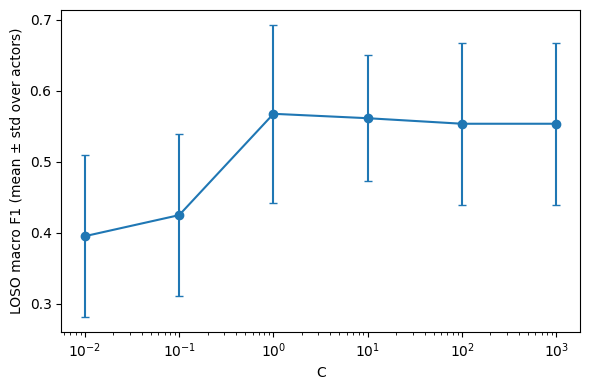

In [7]:
c_values = [0.01, 0.1, 1, 10, 100, 1000]
curve = []
logo = LeaveOneGroupOut()
labels = sorted(y.unique())

for c in c_values:
    fold_scores=[]
    y_test = []
    y_pred = []
    for train_idx, test_idx in logo.split(X, y, groups=groups):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

        pipeline = Pipeline([
            ("scaler", StandardScaler()),
            ("svc", SVC(kernel="rbf", C=c))
        ])

        pipeline.fit(X_train, y_train)
        y_pred = pipeline.predict(X_test)
        fold_scores.append(f1_score(y.iloc[test_idx], y_pred, average="macro", labels=labels, zero_division=0))
    curve.append({"C": c, "mean_macro_f1": np.mean(fold_scores), "std": np.std(fold_scores, ddof=1)})
curve_df = pd.DataFrame(curve)
print(curve_df.round(3).to_string(index=False))

plt.figure(figsize=(6, 4))
plt.errorbar(curve_df["C"], curve_df["mean_macro_f1"], yerr=curve_df["std"], marker="o", capsize=3)
plt.xscale("log"); plt.xlabel("C"); plt.ylabel("LOSO macro F1 (mean ± std over actors)")
plt.tight_layout(); plt.show()
        
    


The best value of the curve (macro F1 of 0.568 at C = 1) is an optimistic estimate because the same LOSO folds were used to choose C and to report its performance. Each point of the curve is a noisy estimate, since it is an average over only 20 actors whose scores differ a lot. Picking the highest of six noisy estimates favours the one that happened to be lucky on these actors, so its expected score on a new actor is lower. The 20 actors have influenced the choice of C, so they are no longer an independent test of it. An unbiased estimate needs a choice of C made without the actors that are used to evaluate it.

Question 4.6
Nested procedure (Figure 5c). In each outer LOSO fold, choose C with GridSearchCV on the training actors only, with an inner GroupKFold(5) that keeps the videos of each actor in the same inner fold; then evaluate the chosen model on the held-out actor. Report the outer macro F1 (mean and standard deviation), the value of C chosen in each outer fold and the mean of the best inner scores [5].

In [8]:
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import GroupKFold

c_values = [0.01, 0.1, 1, 10, 100, 1000]
parameters = {'svc__C': c_values}

outer_results=[]

for train_idx, test_idx in logo.split(X, y, groups=groups):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
    groups_train = groups.iloc[train_idx]

    pipeline = Pipeline([
                ("scaler", StandardScaler()),
                ("svc", SVC(kernel="rbf"))
    ])
    gs = GridSearchCV(pipeline, parameters, scoring="f1_macro", cv=GroupKFold(n_splits=5), n_jobs=-1)

    gs.fit(X_train, y_train, groups=groups_train)
    y_pred = gs.predict(X_test)
    outer_results.append({
        "actor": groups.iloc[test_idx].iloc[0],
        "best_C": gs.best_params_["svc__C"],
        "inner_best_f1": gs.best_score_,
        "outer_f1": f1_score(y_test, y_pred, average="macro",
                             labels=sorted(y.unique()), zero_division=0),
    })

res46 = pd.DataFrame(outer_results)
print(res46.round(3).to_string(index=False))
print(f"Outer macro F1: {res46['outer_f1'].mean():.3f} ± {res46['outer_f1'].std():.3f}")
print(f"Mean best inner F1: {res46['inner_best_f1'].mean():.3f}")
print("Chosen C counts:\n", res46["best_C"].value_counts().sort_index())

actor  best_C  inner_best_f1  outer_f1
   02       1          0.571     0.538
   03       1          0.567     0.526
   04       1          0.567     0.513
   05       1          0.561     0.541
   06       1          0.582     0.351
   07       1          0.584     0.574
   08       1          0.588     0.544
   09       1          0.584     0.674
   10       1          0.578     0.881
   11       1          0.592     0.397
   12       1          0.574     0.598
   13       1          0.577     0.553
   14       1          0.581     0.597
   15       1          0.606     0.395
   18      10          0.571     0.503
   19      10          0.565     0.542
   20       1          0.556     0.618
   21     100          0.556     0.713
   22      10          0.570     0.541
   23       1          0.567     0.498
Outer macro F1: 0.555 ± 0.116
Mean best inner F1: 0.575
Chosen C counts:
 best_C
1      16
10      3
100     1
Name: count, dtype: int64


Question 4.7 Repeat 4.6 with an inner StratifiedKFold(5) that ignores the actor. Compare with 4.6: the values of 
C chosen, the inner estimates and the outer scores. Explain what happened. What does it imply for 
every other decision made with cross-validation in this project?

In [9]:
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import StratifiedKFold

c_values = [0.01, 0.1, 1, 10, 100, 1000]
parameters = {'svc__C': c_values}

outer_results=[]

for train_idx, test_idx in logo.split(X, y, groups=groups):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
    groups_train = groups.iloc[train_idx]

    pipeline = Pipeline([
                ("scaler", StandardScaler()),
                ("svc", SVC(kernel="rbf"))
    ])
    gs = GridSearchCV(pipeline, parameters, scoring="f1_macro", cv=StratifiedKFold(n_splits=5), n_jobs=-1)

    gs.fit(X_train, y_train, groups=groups_train)
    y_pred = gs.predict(X_test)
    outer_results.append({
        "actor": groups.iloc[test_idx].iloc[0],
        "best_C": gs.best_params_["svc__C"],
        "inner_best_f1": gs.best_score_,
        "outer_f1": f1_score(y_test, y_pred, average="macro",
                             labels=sorted(y.unique()), zero_division=0),
    })

res47 = pd.DataFrame(outer_results)
print(res47.round(3).to_string(index=False))
print(f"Outer macro F1: {res47['outer_f1'].mean():.3f} ± {res47['outer_f1'].std():.3f}")
print(f"Mean best inner F1: {res47['inner_best_f1'].mean():.3f}")
print("Chosen C counts:\n", res47["best_C"].value_counts().sort_index())

c:\Users\rjorg\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\model_selection\_split.py:877: UserWarning: The groups parameter is ignored by StratifiedKFold
  warnings.warn(
c:\Users\rjorg\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\model_selection\_split.py:877: UserWarning: The groups parameter is ignored by StratifiedKFold
  warnings.warn(
c:\Users\rjorg\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\model_selection\_split.py:877: UserWarning: The groups parameter is ignored by StratifiedKFold
  warnings.warn(
c:\Users\rjorg\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\model_selection\_split.py:877: UserWarning: The groups parameter is ignored by StratifiedKFold
  warnings.warn(
c:\Users\rjorg\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\model_selection\_split.py:877: UserWarning: The groups parameter is ignored by StratifiedKFold
  warnings.warn(
c:\Users\rjorg\AppData\Local\Progra

actor  best_C  inner_best_f1  outer_f1
   02     100          0.878     0.705
   03     100          0.886     0.454
   04      10          0.879     0.592
   05      10          0.884     0.595
   06     100          0.882     0.339
   07     100          0.887     0.606
   08     100          0.877     0.479
   09     100          0.879     0.616
   10     100          0.882     0.810
   11     100          0.876     0.566
   12     100          0.875     0.567
   13      10          0.874     0.519
   14     100          0.883     0.462
   15     100          0.879     0.406
   18      10          0.869     0.503
   19      10          0.878     0.542
   20     100          0.873     0.612
   21     100          0.879     0.713
   22     100          0.878     0.452
   23     100          0.868     0.542
Outer macro F1: 0.554 ± 0.111
Mean best inner F1: 0.878
Chosen C counts:
 best_C
10      5
100    15
Name: count, dtype: int64


We can see that the C values chosen when using StratifiedKFold are 10 and 100, in contrast to when using GroupKFold which mostly choses 1. We can also see that the inner score is much higher then in 4.6 but the outer score is almost unchanged. This probably due to leakage and overfitting. Since, StratifiedKFold ignores actors, the model is trained on actors it is also tested on, which allows the model to overfit and obtain an optimistic inner score.